# dθ/dQ versus interpolation mesh

`SWEEPS` maps a label to a sweep folder; it reads every `nk_*.npz` there. Filled
markers: base-end estimate; open: mode-end estimate (their spread is a linearity test, not a validity test).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "axion_phonon/axion.py").exists())
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT))

In [ ]:
# Y2Ir2O7 modes, Q = 0.01 Ang, production A(R) (Jae-Mo's formula from the .chk, shared base centres): LDA vs PBE
M = DATA / "Y2Ir2O7/phonon/GM2-"
SWEEPS = {
    "mode 1, LDA (212982)": M / "mode1/Q_0.01A/lda/w90_trial02_212982/nk_sweep_tif_shared_ws",
    "mode 1, PBE (212996)": M / "mode1/Q_0.01A/pbe/w90_trial02_212996/nk_sweep_tif_shared_ws",
    "mode 2, LDA (212994)": M / "mode2/Q_0.01A/lda/w90_trial02_212994/nk_sweep_tif_shared_ws",
    "mode 3, LDA (212995)": M / "mode3/Q_0.01A/lda/w90_trial02_212995/nk_sweep_tif_shared_ws",
    "mode 3, PBE (213002)": M / "mode3/Q_0.01A/pbe/w90_trial02_213002/nk_sweep_tif_shared_ws",
}

NK_MIN = 6

mode 1, LDA (212982): nk=4: -0.01953/-0.01945, nk=6: -0.01828/-0.01841, nk=8: -0.01761/-0.01778, nk=10: -0.01799/-0.01811, nk=12: -0.01798/-0.01810
mode 1, PBE (212996): nk=4: -0.01760/-0.01754, nk=6: -0.01775/-0.01784, nk=8: -0.01731/-0.01744, nk=10: -0.01752/-0.01762, nk=12: -0.01752/-0.01761
mode 2, LDA (212994): nk=4: +0.02972/+0.03127, nk=6: +0.05357/+0.05419, nk=8: +0.05288/+0.05351, nk=10: +0.05383/+0.05450, nk=12: +0.05384/+0.05450
mode 3, LDA (212995): nk=4: +0.06069/+0.06256, nk=6: +0.06553/+0.06641, nk=8: +0.06563/+0.06656, nk=10: +0.06502/+0.06596, nk=12: +0.06502/+0.06596
mode 3, PBE (213002): nk=4: +0.05465/+0.05607, nk=6: +0.05874/+0.05942, nk=8: +0.05851/+0.05924, nk=10: +0.05810/+0.05884, nk=12: +0.05810/+0.05884


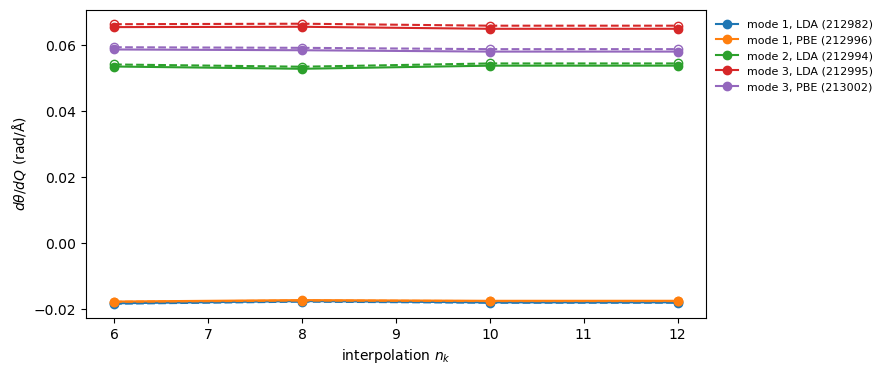

In [3]:
def load_sweep(folder):
    rows = []
    for path in folder.glob("nk_*.npz"):
        data = np.load(path, allow_pickle=True)
        rows.append((int(data["nk"]) if "nk" in data.files else int(path.stem[3:]), np.asarray(data["dtheta"]).real))
    rows.sort()
    return np.array([n for n, _ in rows]), np.array([d for _, d in rows])


fig, ax = plt.subplots(figsize=(8, 4))
for i, (label, folder) in enumerate(SWEEPS.items()):
    nks, dtheta = load_sweep(folder)
    keep = nks >= NK_MIN
    ax.plot(nks[keep], dtheta[keep, 0], "o-", color=f"C{i}", label=label)
    ax.plot(nks[keep], dtheta[keep, 1], "o--", color=f"C{i}", mfc="none")
    print(f"{label}: " + ", ".join(f"nk={n}: {d[0]:+.5f}/{d[1]:+.5f}" for n, d in zip(nks, dtheta)))
ax.set(xlabel="interpolation $n_k$", ylabel=r"$d\theta/dQ$ (rad/Å)")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()